In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression



In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("/home/amir/Downloads/data_set/NASA_JPL_Dataset.csv")
df.head()
y = df["rms"].max()
a = df.describe()["rms"]
rms_avg = a["mean"]
print(rms_avg)
rms_std = a["std"]
print(rms_std)

treshhold = rms_avg + 2 * rms_std
print(treshhold)

cleaner_version = df[df["rms"] < treshhold]


0.5607640924613136
0.09878578641513272
0.7583356652915791


In [3]:

cleaner_version.describe()

temp = cleaner_version.describe()

diameter_sigma_column = temp["diameter_sigma"]
diameter_sigma_std = diameter_sigma_column["std"]
diameter_sigma_avg = diameter_sigma_column["mean"]

print(diameter_sigma_avg)
print(diameter_sigma_std)

diameter_treshhold =2 * diameter_sigma_std + diameter_sigma_avg

(cleaner_version["diameter_sigma"] > diameter_treshhold).sum()

super_cleaner_version = cleaner_version[cleaner_version["diameter_sigma"] < diameter_treshhold]

print(super_cleaner_version.shape)
print(df.shape)




0.4560478451565165
0.2122228078913105
(875842, 30)
(921425, 30)


In [4]:
pd.set_option('display.max_columns', None)  
pd.set_option('display.width', None)        

In [5]:
input = super_cleaner_version.drop(columns=["diameter"])
output = super_cleaner_version["diameter"]

output


0          9.300
1         11.077
2         11.036
3          9.822
4         10.456
           ...  
921420     1.297
921421     1.111
921422     0.286
921423     1.417
921424     1.315
Name: diameter, Length: 875842, dtype: float64

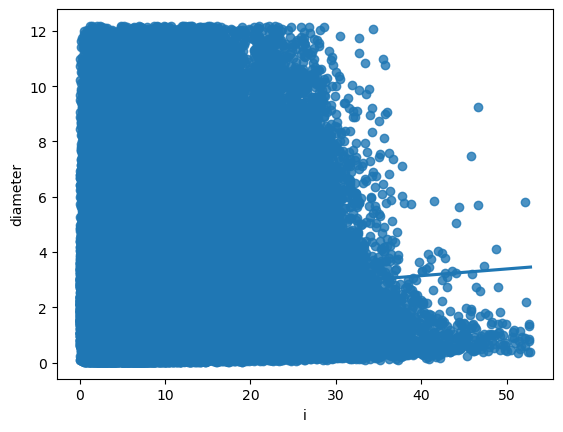

In [5]:
sns.regplot(data = super_cleaner_version , x= "i" , y = "diameter")
plt.show()


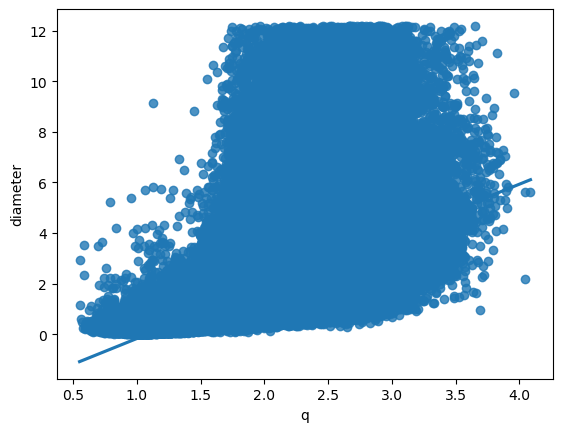

In [6]:
sns.regplot(data = super_cleaner_version , x= "q" , y = "diameter")
plt.show()

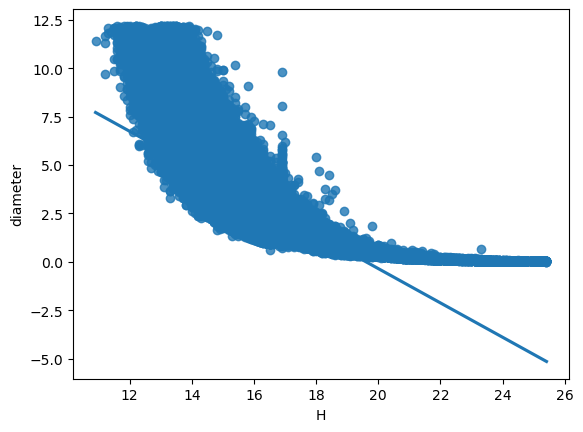

In [7]:
sns.regplot(data = super_cleaner_version , x= "H" , y = "diameter")
plt.show()

In [6]:
cleaner_version.columns

Index(['full_name', 'neo', 'pha', 'class', 'H', 'e', 'a', 'q', 'i', 'om', 'w',
       'ma', 'ad', 'n', 'per_y', 'moid', 'sigma_e', 'sigma_a', 'sigma_q',
       'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad', 'sigma_n',
       'sigma_per', 'diameter_sigma', 'rms', 'albedo', 'diameter'],
      dtype='object')

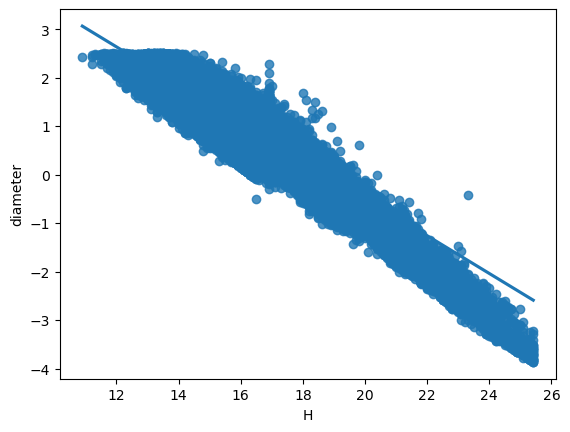

In [7]:
sns.regplot(data = super_cleaner_version , x=super_cleaner_version["H"] , y = np.log(super_cleaner_version["diameter"]))
plt.show()

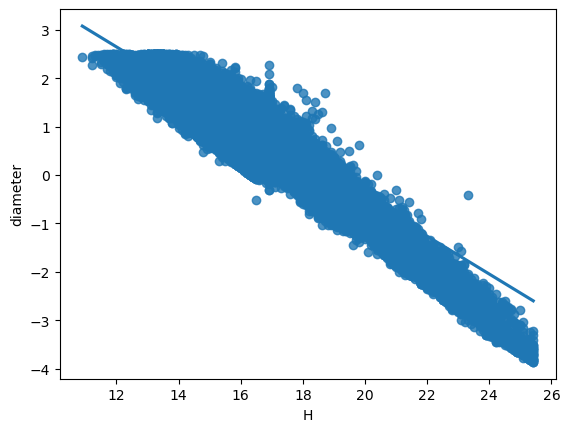

In [10]:
sns.regplot(data = df , x=df["H"] , y = np.log(df["diameter"]))
plt.show()

In [8]:
super_cleaner_version.describe()

,H,e,a,q,i,om,w,ma,ad,n,per_y,moid,sigma_e,sigma_a,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_per,diameter_sigma,rms,albedo,diameter
count,875842.000000,875842.000000,875842.000000,875842.000000,875842.000000,875842.000000,875842.000000,875842.000000,875842.000000,875842.000000,875842.000000,875842.000000,8.758420e+05,8.758420e+05,8.758420e+05,8.758420e+05,875842.000000,875842.000000,8.758420e+05,8.758420e+05,8.758420e+05,8.758420e+05,875842.000000,875842.000000,875842.000000,875842.000000
mean,16.920687,0.153346,2.661008,2.255325,8.821320,168.500753,181.225198,176.626432,3.066691,0.234392,4.367814,1.268502,7.577598e-06,1.769805e-05,1.744872e-05,1.180411e-04,0.000309,0.002709,4.882405e-03,2.130336e-05,2.001327e-06,1.552944e-02,0.433337,0.556138,0.085953,2.382397
std,1.310812,0.080669,0.342417,0.376532,6.238999,102.851466,103.885021,105.263232,0.433254,0.047123,0.841643,0.370947,2.219909e-05,5.455657e-05,5.024101e-05,3.296106e-04,0.000670,0.007400,1.446569e-02,6.571756e-05,6.096355e-06,4.777781e-02,0.175084,0.094983,0.064158,1.426769
min,10.900000,0.000060,1.562516,0.549429,0.007744,0.000025,0.000130,-67.136826,1.595898,0.105567,1.953192,0.000076,1.459500e-09,1.060000e-10,3.856200e-09,1.903000e-07,0.000001,0.000004,2.103800e-07,1.597000e-10,3.402700e-11,7.882500e-08,0.003000,0.000000,0.001000,0.021000
25%,16.124000,0.094452,2.386912,1.972548,4.092478,80.750147,91.384308,83.783888,2.777673,0.192815,3.687762,0.986082,5.508100e-08,2.032500e-08,1.462000e-07,6.123000e-06,0.000037,0.000058,2.570900e-05,2.325700e-08,2.790725e-09,1.776600e-05,0.310000,0.519583,0.052000,1.483000
50%,16.900000,0.146120,2.636963,2.209312,7.193552,159.767784,182.150135,174.096771,3.028028,0.230170,4.282173,1.236960,8.171600e-08,3.809200e-08,2.271700e-07,8.688800e-06,0.000066,0.000105,4.861200e-05,4.317500e-08,4.638000e-09,3.457300e-05,0.419000,0.566120,0.063000,2.050000
75%,17.700000,0.199574,2.967401,2.546678,12.209519,252.332551,271.331020,268.337479,3.340146,0.267270,5.111784,1.553930,1.954075e-07,8.676600e-08,5.383875e-07,1.470875e-05,0.000151,0.000275,1.408200e-04,9.893900e-08,9.738175e-09,8.095775e-05,0.550000,0.611940,0.085000,2.870000
max,25.414000,0.663066,4.433872,4.087681,52.780069,359.999793,359.999646,491.618014,5.879479,0.504623,9.336475,3.143950,8.294701e-05,2.032200e-04,1.841739e-04,1.219546e-03,0.002533,0.027014,5.338743e-02,2.449053e-04,2.240696e-05,1.776327e-01,0.880000,0.758330,0.534000,12.181000


In [9]:
super_cleaner_version.head()

,full_name,neo,pha,class,H,e,a,q,i,om,w,ma,ad,n,per_y,moid,sigma_e,sigma_a,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_per,diameter_sigma,rms,albedo,diameter
0,228 Agathe,N,N,MBA,12.2,0.241806,2.201366,1.669063,2.536735,313.299574,19.025757,61.740291,2.733669,0.301763,3.266229,0.658827,3.795700e-08,4.910800e-09,8.470000e-08,0.000004,0.000078,0.000079,0.000007,6.098200e-09,1.009800e-09,0.000004,0.800,0.45723,0.2082,9.300
1,244 Sita,N,N,MBA,11.9,0.137159,2.174534,1.876277,2.845077,208.965314,166.427697,116.239421,2.472791,0.307365,3.206694,0.877480,2.841600e-08,4.699100e-09,6.148300e-08,0.000003,0.000077,0.000078,0.000016,5.343600e-09,9.963000e-10,0.000004,0.022,0.41912,0.2560,11.077
2,281 Lucretia,N,N,MBA,12.0,0.132129,2.188327,1.899185,5.302024,31.395143,16.536134,228.594281,2.477468,0.304464,3.237251,0.909437,3.389300e-08,4.997400e-09,7.404500e-08,0.000004,0.000041,0.000045,0.000018,5.657700e-09,1.042900e-09,0.000004,0.145,0.39876,0.2260,11.036
3,290 Bruna,N,N,MBA,12.0,0.257171,2.338338,1.736985,22.322541,10.370025,105.348351,197.508486,2.939691,0.275641,3.575766,0.873866,3.648400e-08,7.622200e-09,8.529300e-08,0.000008,0.000011,0.000019,0.000015,9.582400e-09,1.347700e-09,0.000006,0.130,0.30651,0.3140,9.822
4,291 Alice,N,N,MBA,11.5,0.092282,2.222746,2.017625,1.856198,161.594982,332.120495,171.293238,2.427866,0.297420,3.313926,1.031920,3.022200e-08,5.331600e-09,6.687200e-08,0.000004,0.000112,0.000115,0.000023,5.823600e-09,1.070100e-09,0.000004,0.419,0.40410,0.4250,10.456


In [10]:
super_cleaner_version = pd.get_dummies(df, columns=['neo', 'pha', 'class'], drop_first=True)


In [11]:
super_cleaner_version.head()

,full_name,H,e,a,q,i,om,w,ma,ad,n,per_y,moid,sigma_e,sigma_a,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_per,diameter_sigma,rms,albedo,diameter,neo_Y,pha_Y,class_MBA,class_OMB,class_Other
0,228 Agathe,12.2,0.241806,2.201366,1.669063,2.536735,313.299574,19.025757,61.740291,2.733669,0.301763,3.266229,0.658827,3.795700e-08,4.910800e-09,8.470000e-08,0.000004,0.000078,0.000079,0.000007,6.098200e-09,1.009800e-09,0.000004,0.800,0.45723,0.2082,9.300,False,False,True,False,False
1,244 Sita,11.9,0.137159,2.174534,1.876277,2.845077,208.965314,166.427697,116.239421,2.472791,0.307365,3.206694,0.877480,2.841600e-08,4.699100e-09,6.148300e-08,0.000003,0.000077,0.000078,0.000016,5.343600e-09,9.963000e-10,0.000004,0.022,0.41912,0.2560,11.077,False,False,True,False,False
2,281 Lucretia,12.0,0.132129,2.188327,1.899185,5.302024,31.395143,16.536134,228.594281,2.477468,0.304464,3.237251,0.909437,3.389300e-08,4.997400e-09,7.404500e-08,0.000004,0.000041,0.000045,0.000018,5.657700e-09,1.042900e-09,0.000004,0.145,0.39876,0.2260,11.036,False,False,True,False,False
3,290 Bruna,12.0,0.257171,2.338338,1.736985,22.322541,10.370025,105.348351,197.508486,2.939691,0.275641,3.575766,0.873866,3.648400e-08,7.622200e-09,8.529300e-08,0.000008,0.000011,0.000019,0.000015,9.582400e-09,1.347700e-09,0.000006,0.130,0.30651,0.3140,9.822,False,False,True,False,False
4,291 Alice,11.5,0.092282,2.222746,2.017625,1.856198,161.594982,332.120495,171.293238,2.427866,0.297420,3.313926,1.031920,3.022200e-08,5.331600e-09,6.687200e-08,0.000004,0.000112,0.000115,0.000023,5.823600e-09,1.070100e-09,0.000004,0.419,0.40410,0.4250,10.456,False,False,True,False,False


In [12]:
super_cleaner_version1 = super_cleaner_version.drop(columns = ["sigma_e" ,"sigma_a" ,"sigma_q" ,"sigma_om" ,"sigma_w" ,"sigma_i" ,"sigma_ma" ,"sigma_i" ,"sigma_ad" ,"sigma_n" ,"sigma_per" ,"diameter_sigma" , "rms" ])

In [13]:
super_cleaner_version1.head()

,full_name,H,e,a,q,i,om,w,ma,ad,n,per_y,moid,albedo,diameter,neo_Y,pha_Y,class_MBA,class_OMB,class_Other
0,228 Agathe,12.2,0.241806,2.201366,1.669063,2.536735,313.299574,19.025757,61.740291,2.733669,0.301763,3.266229,0.658827,0.2082,9.300,False,False,True,False,False
1,244 Sita,11.9,0.137159,2.174534,1.876277,2.845077,208.965314,166.427697,116.239421,2.472791,0.307365,3.206694,0.877480,0.2560,11.077,False,False,True,False,False
2,281 Lucretia,12.0,0.132129,2.188327,1.899185,5.302024,31.395143,16.536134,228.594281,2.477468,0.304464,3.237251,0.909437,0.2260,11.036,False,False,True,False,False
3,290 Bruna,12.0,0.257171,2.338338,1.736985,22.322541,10.370025,105.348351,197.508486,2.939691,0.275641,3.575766,0.873866,0.3140,9.822,False,False,True,False,False
4,291 Alice,11.5,0.092282,2.222746,2.017625,1.856198,161.594982,332.120495,171.293238,2.427866,0.297420,3.313926,1.031920,0.4250,10.456,False,False,True,False,False


In [ ]:
def sigma_calculator( batch_size , parameter_vector , batch_size_input_df , batch_size_output_df):
    result = np.zeros_like(parameter_vector)
    for i in range(len(batch_size_input_df)):
        
        actual_y = batch_size_output_df[i].item() 
        
        prediction = np.dot(parameter_vector , batch_size_input_df[i])        
        error_term = (actual_y - prediction) 
        
        result = result + error_term * batch_size_input_df[i]
    return result / batch_size

def gradian_desent(learning_rate , parameter_vector , batch_size , batch_size_input_df , batch_size_output_df):
    w = parameter_vector + learning_rate * sigma_calculator(batch_size , parameter_vector , batch_size_input_df , batch_size_output_df)
    return w


n_epochs =100

super_cleaner_version1 = super_cleaner_version1.sample(frac= 1 , random_state= 42).reset_index(drop = True)

x = super_cleaner_version1.drop(columns=["diameter" , "full_name"])
y = super_cleaner_version1["diameter"]

x_train , x_test , y_train , y_test = train_test_split(x , y , test_size= 0.2 , random_state= 42)




scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

x_train_scaled = np.hstack((x_train_scaled, np.ones((x_train_scaled.shape[0], 1))))
x_test_scaled = np.hstack((x_test_scaled, np.ones((x_test_scaled.shape[0], 1))))

batch_size = 32
first = 0
w = np.zeros(x_train_scaled.shape[1])

losses = []
for g in range(n_epochs):
    indices = np.arange(len(x_train_scaled))
    np.random.shuffle(indices)
    for i in range(0, len(x_train_scaled), batch_size):
        batch_x = x_train_scaled[i:i+batch_size]
        batch_y = y_train_scaled[i:i+batch_size]

        w = gradian_desent(0.005, w, len(batch_x), batch_x, batch_y)

    y_pred_epoch = np.dot(x_train_scaled, w)
    loss = np.mean((y_train_scaled.flatten() - y_pred_epoch)**2)
    losses.append(loss)

print(w)
y_pred_scaled = np.dot(x_test_scaled, w)
y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1,1))

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)




[-1.04353250e+00  4.33901981e-01  1.14271117e-01  4.37964417e-01
 -2.94944120e-02  2.33212560e-03  7.52965765e-04 -2.87016127e-03
 -2.03422327e-01  4.07186466e-01  8.11271793e-02  9.05552063e-02
 -3.84885705e-01  1.23035228e-01 -2.50734160e-02 -4.06717492e-02
 -1.10891025e-02  1.64281175e-02 -4.13400124e-03]
MSE: 0.3869640479904745
RMSE: 0.6220643439311359
R² Score: 0.8148195584547013


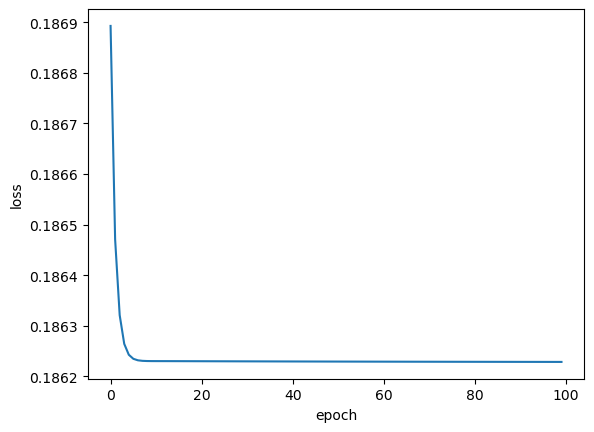

In [37]:

loss_df = loss_df = pd.DataFrame({
    "epoch": range(len(losses)),
    "loss": losses
})


sns.lineplot(data= loss_df , x= "epoch" , y = "loss")
plt.show()

In [24]:
reg = LinearRegression()
reg.fit(x_train_scaled , y_train_scaled)

LinearRegression()

In [25]:

y_pred_scaled_sklearn = reg.predict(x_test_scaled)
y_pred_sklearn = y_scaler.inverse_transform(y_pred_scaled_sklearn.reshape(-1,1))

mse = mean_squared_error(y_test, y_pred_sklearn)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_sklearn)

print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MSE: 0.3799343985665102
RMSE: 0.6163881882113821
R² Score: 0.8154995949115191
